# Camada Gold — EDA e Estatística
**Responsável:** F4 Lucy · **Aprovador:** F1  
Projeto Final de Big Data — DataRoute Recife (UNINASSAU, 6º noturno)

> Regra: use apenas os caminhos de `src/config.py`. Nada de `C:/...` ou `/content/drive/...`.

In [1]:
# Setup padrão (NÃO ALTERAR): funciona local e no Google Colab
import sys
from pathlib import Path
try:
    import google.colab  # noqa: F401
    if not Path('dataroute-recife').exists() and not Path('src').exists():
        !git clone -q https://github.com/pcsdv0/dataroute-recife.git
    if Path('dataroute-recife').exists():
        %cd dataroute-recife
    !pip install -q -r requirements.txt
except ImportError:
    pass
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import *          # caminhos relativos oficiais
from src.utils import ler_csv_robusto, salvar_csv
if not SILVER_SINISTROS.exists():  # gera Bronze -> Silver -> Gold se ainda não existir
    from src.pipeline import executar
    executar()

In [2]:
import pandas as pd
from src import gold
df = pd.read_csv(SILVER_SINISTROS, parse_dates=['data'])
tabelas = gold.run(df)['tabelas']
tabelas['top10_bairros']

,bairro,sinistros,vitimas,fatais,ups,letalidade_pct
0,BOA VIAGEM,7392,2415,27,14254,0.37
1,IMBIRIBEIRA,3727,1472,17,7832,0.46
2,SANTO AMARO,3053,1385,11,6935,0.36
3,AFOGADOS,2300,850,13,4787,0.57
4,MADALENA,2227,877,11,4660,0.49
5,BOA VISTA,2272,755,11,4591,0.48
6,CASA AMARELA,1675,815,8,3993,0.48
7,SAO JOSE,1563,676,6,3535,0.38
8,IPSEP,1586,674,12,3493,0.76
9,PINA,1623,616,7,3427,0.43


In [3]:
# Estatística descritiva
df[['vitimas','vitimasfatais','indice_severidade','hora']].describe()

,vitimas,vitimasfatais,indice_severidade,hora
count,60225.000000,60225.000000,60225.000000,49279.000000
mean,0.412985,0.004815,2.173815,13.075773
std,0.629226,0.075424,1.710803,4.910806
min,0.000000,0.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,9.000000
50%,0.000000,0.000000,1.000000,13.000000
75%,1.000000,0.000000,4.000000,17.000000
max,24.000000,6.000000,13.000000,23.000000


In [4]:
# Comparação entre anos: use só sinistros COM vítima (o Bate-Pronto tirou os SEM vítima da base a partir de jul/2020)
com_vitima = df[df['classificacao'] != 'SEM VITIMA']
com_vitima.groupby('ano').size()


ano
2015    1192
2016    1877
2017    1981
2018    1864
2019    2064
2020    1614
2021    1655
2022    1906
2023    3054
2024    4372
dtype: int64

## F4 — Estatística dos 4 objetivos
**Pergunta do projeto:** onde, quando e em que condições os sinistros são mais graves, como apoio à fiscalização preventiva e à política de segurança viária.

| Objetivo | Pergunta | Bloco |
|---|---|---|
| 1 | **Quando (tempo longo):** como evoluíram sinistros e óbitos entre 2015 e 2024? | Evolução temporal |
| 2 | **Quando (ciclo diário/semanal):** em que dias e horários são mais frequentes e mais graves? | Dia da semana e hora |
| 3 | **Onde:** quais bairros e corredores arteriais concentram sinistros e gravidade? | Bairros e corredores |
| 4 | **Em que condições:** quem são as vítimas/veículos mais graves e que variáveis se relacionam? | Perfil e correlações |

Premissas: comparações entre anos usam só sinistros **COM vítima** (Bate-Pronto, jul/2020). Fonte: chamados de sinistros da CTTU, Portal de Dados Abertos do Recife (ODbL).

In [5]:
import unicodedata
import numpy as np
import pandas as pd
from scipy import stats

def norm(s):
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()

def achar(*chaves, excluir=()):
    """Colunas de df cujo nome contém alguma das chaves (sem acento, minúsculas)."""
    return [c for c in df.columns
            if any(k in norm(c).lower() for k in chaves) and c not in excluir]

def cramer_v(tab):
    chi2 = stats.chi2_contingency(tab)[0]
    return np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))

def wilson(k, n):
    if n == 0:
        return (np.nan, np.nan)
    c = stats.binomtest(int(k), int(n)).proportion_ci(method='wilson')
    return c.low * 100, c.high * 100

com_vitima = df[df['classificacao'] != 'SEM VITIMA'].copy()
com_vitima['fatal'] = com_vitima['vitimasfatais'] > 0
com_vitima['mes'] = com_vitima['data'].dt.to_period('M')
com_vitima['dia_semana'] = com_vitima['data'].dt.dayofweek
print('Colunas da base:', list(df.columns))

Colunas da base: ['data', 'ano', 'mes', 'dia_semana', 'hora', 'turno', 'horario_pico', 'bairro', 'endereco', 'classificacao', 'tipo_acidente', 'situacao', 'auto', 'moto', 'ciclom', 'ciclista', 'pedestre', 'onibus', 'caminhao', 'vitimas', 'vitimasfatais', 'vitima_fatal', 'indice_severidade', 'tempo_clima', 'situacao_semaforo', 'condicao_via', 'arquivo_origem']


### Qualidade dos dados e limitações (leia antes das conclusões)

In [6]:
print(f'Registros: {len(df):,} | com vítima: {len(com_vitima):,}')
print('Período:', df['data'].min().date(), '->', df['data'].max().date())

nulos = (df.isna().mean() * 100).round(1)
print('\nColunas com valores nulos (%):')
print(nulos[nulos > 0].sort_values(ascending=False).to_string())

# severidade é derivada da classificação? (se sim, não correlacionar severidade com vítimas/óbitos)
print('\nSeveridade por classificação:')
print(df.groupby('classificacao')['indice_severidade'].agg(['count', 'min', 'max', 'nunique']))

# óbitos por ano na base: compare com os relatórios oficiais da CTTU/COMPAT
obitos_ano = df.groupby('ano')['vitimasfatais'].sum()
print('\nÓbitos registrados na base por ano:')
print(obitos_ano.to_string())
print('A base são CHAMADOS de sinistro. O próprio portal avisa que ela pode divergir dos relatórios anuais')
print('de segurança viária da CTTU, e óbitos ocorridos depois do atendimento não entram aqui.')
print('Use estes números para comparar padrões, não como contagem oficial de mortes.')

Registros: 60,225 | com vítima: 21,579
Período: 2015-06-01 -> 2024-12-31

Colunas com valores nulos (%):
hora            18.2
turno           18.2
horario_pico    18.2

Severidade por classificação:
               count  min  max  nunique
classificacao                          
COM VITIMA     21303    4    6        2
SEM VITIMA     38646    1    1        1
VITIMA FATAL     276   13   13        1

Óbitos registrados na base por ano:
ano
2015    24
2016    38
2017    38
2018    28
2019    25
2020    19
2021    24
2022    25
2023    30
2024    39
A base são CHAMADOS de sinistro. O próprio portal avisa que ela pode divergir dos relatórios anuais
de segurança viária da CTTU, e óbitos ocorridos depois do atendimento não entram aqui.
Use estes números para comparar padrões, não como contagem oficial de mortes.


**Interpretação:** a base tem 60.225 sinistros, e 21.579 deles (35,8%) têm vítima. A hora falta em 18,2% dos registros: 2022 não tem hora, e em 2023–2024 a hora vem em formato de 12 horas sem AM/PM, então foi anulada na Silver. Por isso a análise de horário vale só para 2015–2021. O índice de severidade (UPS) é derivado da própria classificação, então não entra nas correlações. Os óbitos ficam entre 19 e 39 por ano e servem para comparar padrões, não como contagem oficial de mortes.

### OBJETIVO 1 — Quando (evolução 2015–2024)

,sinistros,vitimas,fatais,meses_cobertos,sinistros_por_mes,fatais_por_100_vitimas,var_pct_sinistros_mes
ano,,,,,,,
2015,1192,1386,24,7,170.3,1.73,NaN
2016,1877,2230,38,12,156.4,1.70,-8.2
2017,1981,2389,38,12,165.1,1.59,5.6
2018,1864,2168,28,12,155.3,1.29,-5.9
2019,2064,2402,25,12,172.0,1.04,10.8
2020,1614,1916,19,12,134.5,0.99,-21.8
2021,1655,1927,24,12,137.9,1.25,2.5
2022,1906,2256,25,12,158.8,1.11,15.2
2023,3054,3488,30,12,254.5,0.86,60.3


Tendência mensal 2015-2024 (Spearman): rho=0.39, p=2.09e-05
Sinistros/mês 2023-24 vs 2021-22: razão=2.09, p=6.97e-304
Óbitos/mês   2023-24 vs 2021-22: razão=1.41, p=0.0798
Se sinistros sobem muito e óbitos não, suspeitar de mudança de registro/cobertura, não de piora real.


<Axes: title={'center': 'Sinistros com vítima por mês'}, xlabel='mes'>

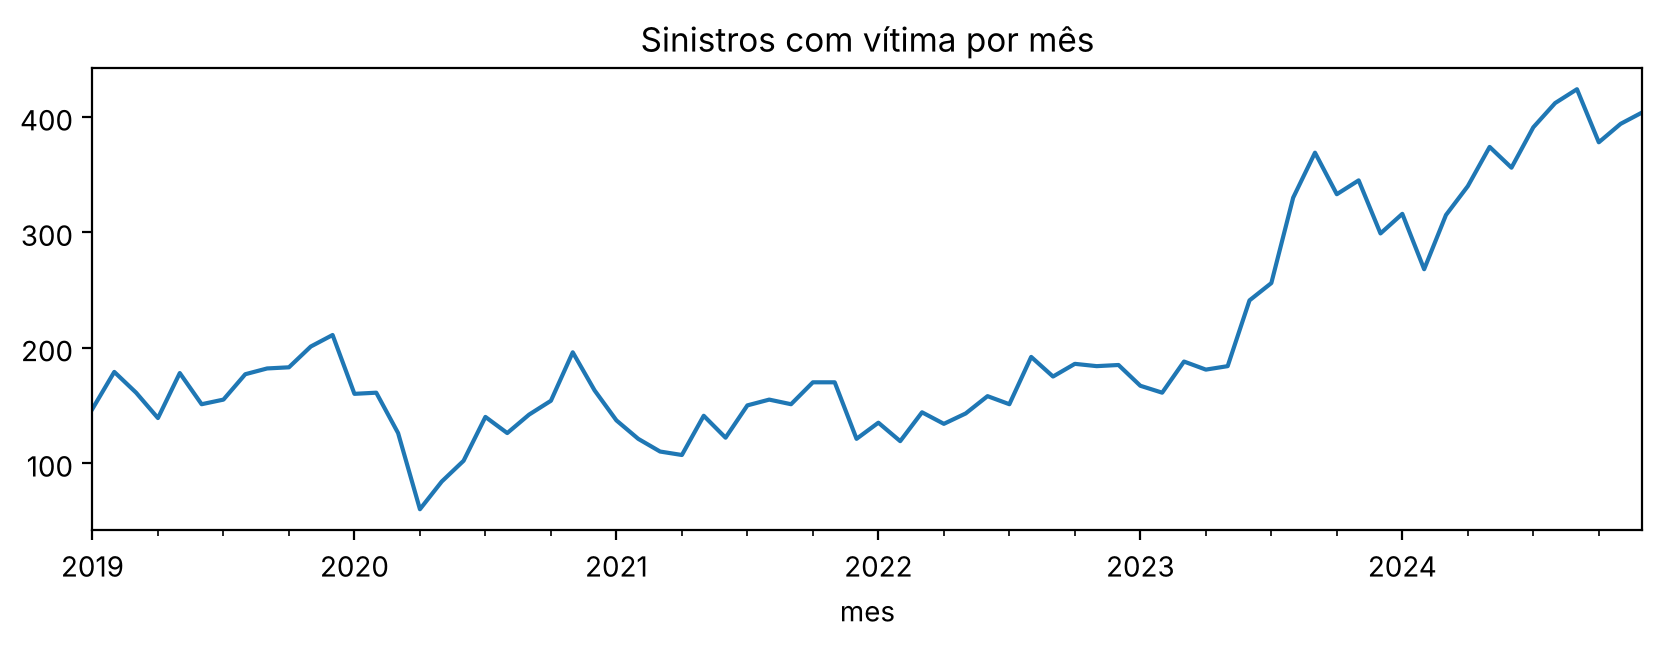

In [7]:
meses_por_ano = com_vitima.groupby('ano')['mes'].nunique()
anual = com_vitima.groupby('ano').agg(
    sinistros=('fatal', 'size'),
    vitimas=('vitimas', 'sum'),
    fatais=('vitimasfatais', 'sum'),
)
anual['meses_cobertos'] = meses_por_ano
anual['sinistros_por_mes'] = (anual['sinistros'] / anual['meses_cobertos']).round(1)
anual['fatais_por_100_vitimas'] = (anual['fatais'] / anual['vitimas'] * 100).round(2)
anual['var_pct_sinistros_mes'] = (anual['sinistros_por_mes'].pct_change() * 100).round(1)
display(anual)

mensal = com_vitima.groupby('mes').size()
rho, p = stats.spearmanr(np.arange(len(mensal)), mensal.values)
print(f'Tendência mensal 2015-2024 (Spearman): rho={rho:.2f}, p={p:.3g}')

def razao(anos_a, anos_b, so_fatais=False):
    a = com_vitima[com_vitima['ano'].isin(anos_a)]
    b = com_vitima[com_vitima['ano'].isin(anos_b)]
    ka = a['vitimasfatais'].sum() if so_fatais else len(a)
    kb = b['vitimasfatais'].sum() if so_fatais else len(b)
    ma, mb = a['mes'].nunique(), b['mes'].nunique()
    res = stats.binomtest(int(ka), int(ka + kb), p=ma / (ma + mb))
    return (ka / ma) / (kb / mb), res.pvalue

r_s, p_s = razao([2023, 2024], [2021, 2022])
r_f, p_f = razao([2023, 2024], [2021, 2022], so_fatais=True)
print(f'Sinistros/mês 2023-24 vs 2021-22: razão={r_s:.2f}, p={p_s:.3g}')
print(f'Óbitos/mês   2023-24 vs 2021-22: razão={r_f:.2f}, p={p_f:.3g}')
print('Se sinistros sobem muito e óbitos não, suspeitar de mudança de registro/cobertura, não de piora real.')

mensal.loc['2019-01':].plot(figsize=(10, 3), title='Sinistros com vítima por mês')

**Interpretação:** os sinistros com vítima crescem ao longo da série (Spearman ρ = 0,39; p < 0,001), mas o crescimento se concentra em 2023–2024. Nesses dois anos o volume mensal é 2,09 vezes o de 2021–2022 (p < 0,001), enquanto os óbitos sobem só 1,41 vez, sem significância estatística (p = 0,08). Com isso a letalidade cai de 1,73 óbito por 100 vítimas (2015) para 0,83 (2024). O padrão sugere que parte do salto vem de mudança no registro (a base passa a ter protocolo a partir de 2022), e não de uma piora equivalente na segurança viária. Em 2020 há queda de 21,8% no volume mensal, compatível com a redução de circulação na pandemia.

### OBJETIVO 2 — Quando (dia da semana e horário)

,sinistros,fatais,pct_sinistros,pct_fatal
Seg,3419,58,15.8,1.70
Ter,3454,31,16.0,0.90
Qua,3253,21,15.1,0.65
Qui,3226,47,14.9,1.46
Sex,3412,42,15.8,1.23
Sáb,2728,40,12.6,1.47
Dom,2087,37,9.7,1.77


Sinistros distribuídos uniformemente pela semana? chi2=495.1, p=9.69e-104
Dia da semana x óbito: p=0.000389, Cramér V=0.034


,sinistros,fatais,vitimas_media,pct_sinistros,pct_fatal,ic95
periodo,,,,,,
Madrugada (0-5h),620,42,1.316,5.1,6.77,5.05-9.03
Manhã (6-11h),4127,42,1.158,33.7,1.02,0.75-1.37
Tarde (12-17h),4470,48,1.162,36.6,1.07,0.81-1.42
Noite (18-23h),3012,60,1.198,24.6,1.99,1.55-2.56


Período x óbito: chi2=127.40, p=1.97e-27, Cramér V=0.102
Pico: 8h (949 sinistros) | menor movimento: 3h
Hora ausente em 43.3% dos sinistros com vítima (excluídos desta análise):
2022 não tem hora, e 2023-2024 têm hora em formato 12 h sem AM/PM. A análise de horário vale para 2015-2021.


<Axes: title={'center': 'Sinistros com vítima por hora'}, xlabel='hora'>

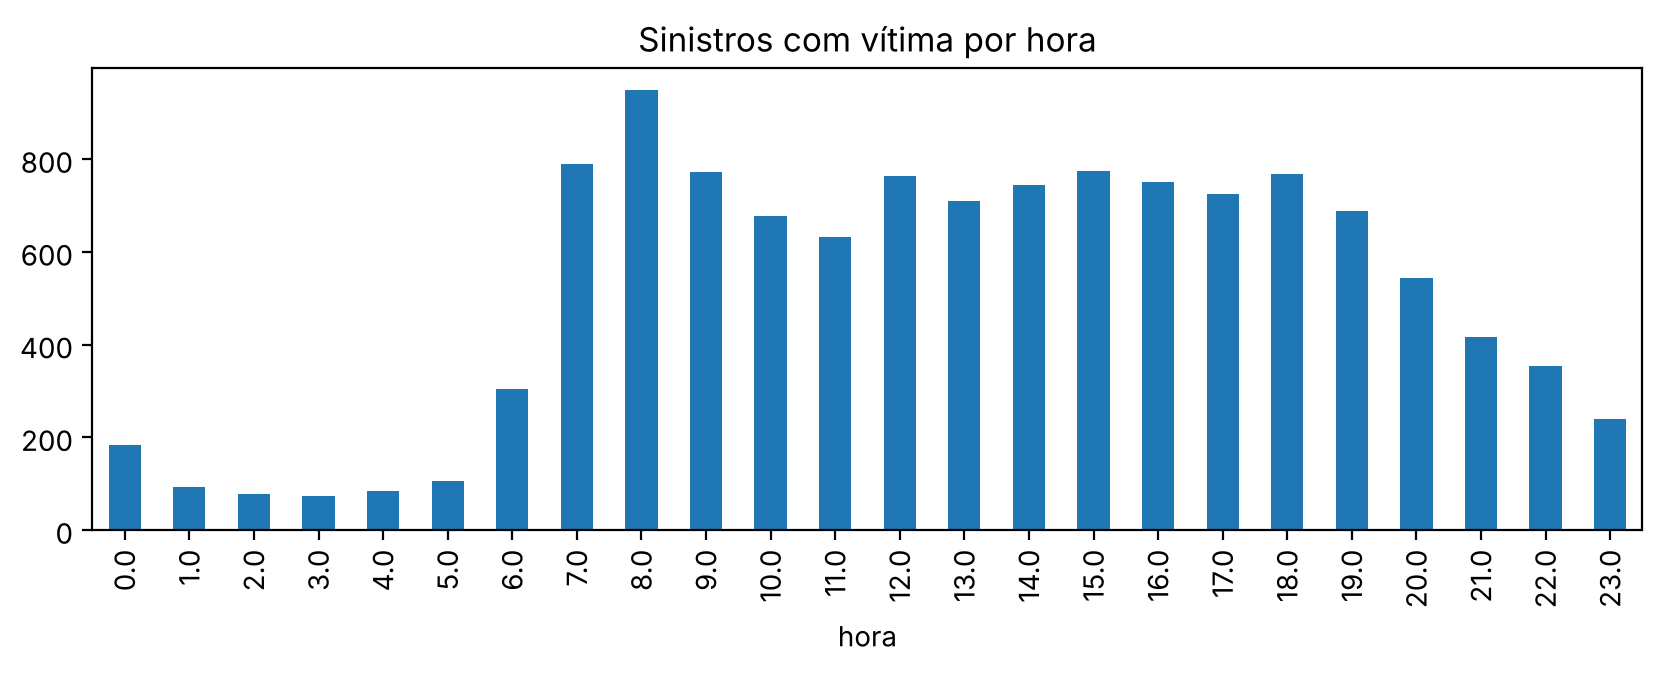

In [8]:
nomes_dia = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
dia = com_vitima.groupby('dia_semana').agg(sinistros=('fatal', 'size'), fatais=('fatal', 'sum'))
dia.index = nomes_dia
dia['pct_sinistros'] = (dia['sinistros'] / dia['sinistros'].sum() * 100).round(1)
dia['pct_fatal'] = (dia['fatais'] / dia['sinistros'] * 100).round(2)
display(dia)
chi2, p = stats.chisquare(dia['sinistros'])
print(f'Sinistros distribuídos uniformemente pela semana? chi2={chi2:.1f}, p={p:.3g}')
tab = pd.crosstab(com_vitima['dia_semana'], com_vitima['fatal'])
print(f'Dia da semana x óbito: p={stats.chi2_contingency(tab)[1]:.3g}, Cramér V={cramer_v(tab):.3f}')

cv = com_vitima.dropna(subset=['hora']).copy()
cv['periodo'] = pd.cut(cv['hora'], bins=[-1, 5, 11, 17, 23],
                       labels=['Madrugada (0-5h)', 'Manhã (6-11h)', 'Tarde (12-17h)', 'Noite (18-23h)'])
perfil = cv.groupby('periodo', observed=True).agg(
    sinistros=('fatal', 'size'), fatais=('fatal', 'sum'), vitimas_media=('vitimas', 'mean'))
perfil['pct_sinistros'] = (perfil['sinistros'] / perfil['sinistros'].sum() * 100).round(1)
perfil['pct_fatal'] = (perfil['fatais'] / perfil['sinistros'] * 100).round(2)
ic = [wilson(k, n) for k, n in zip(perfil['fatais'], perfil['sinistros'])]
perfil['ic95'] = [f'{a:.2f}-{b:.2f}' for a, b in ic]
display(perfil.round(3))

tab = pd.crosstab(cv['periodo'], cv['fatal'])
chi2, p, _, _ = stats.chi2_contingency(tab)
print(f'Período x óbito: chi2={chi2:.2f}, p={p:.3g}, Cramér V={cramer_v(tab):.3f}')
pico = cv.groupby('hora').size()
print(f'Pico: {int(pico.idxmax())}h ({pico.max()} sinistros) | menor movimento: {int(pico.idxmin())}h')
print(f"Hora ausente em {com_vitima['hora'].isna().mean()*100:.1f}% dos sinistros com vítima (excluídos desta análise):")
print('2022 não tem hora, e 2023-2024 têm hora em formato 12 h sem AM/PM. A análise de horário vale para 2015-2021.')
pico.plot(kind='bar', figsize=(10, 3), title='Sinistros com vítima por hora')

**Interpretação:** os sinistros não se distribuem igualmente na semana (χ² = 495; p < 0,001). Cada dia útil concentra de 15% a 16% dos casos, contra 9,7% no domingo. No horário (2015–2021), o pico de volume é às 8h, com 949 sinistros, mas a gravidade se inverte: a madrugada (0h–5h) responde por só 5,1% dos sinistros e tem a maior proporção com óbito, 6,77% (IC 95%: 5,05–9,03). Isso é cerca de 6,6 vezes a manhã (1,02%), e a noite fica em 1,99%. É a associação mais forte entre as variáveis de tempo (V de Cramér = 0,10). Para a fiscalização, o volume pede atenção ao pico da manhã, e a letalidade pede ações noturnas e de madrugada, como controle de velocidade.

### OBJETIVO 3 — Onde (bairros e corredores arteriais)

In [9]:
# --- Bairros ---
cont = com_vitima['bairro'].value_counts()
acum = cont.cumsum() / cont.sum() * 100
n80 = int((acum < 80).sum() + 1)
print(f'Top 10 bairros = {acum.iloc[9]:.1f}% dos sinistros com vítima; {n80} de {len(cont)} bairros somam 80%')

top = tabelas['top10_bairros'].copy()
top['fatais_por_100_vitimas'] = (top['fatais'] / top['vitimas'] * 100).round(2)
ic = [wilson(k, n) for k, n in zip(top['fatais'], top['vitimas'])]
top['ic95_inf'] = [round(a, 2) for a, _ in ic]
top['ic95_sup'] = [round(b, 2) for _, b in ic]
display(top[['bairro', 'sinistros', 'vitimas', 'fatais', 'fatais_por_100_vitimas', 'ic95_inf', 'ic95_sup']])
tab = np.array([top['fatais'], top['vitimas'] - top['fatais']]).T
chi2, p, _, _ = stats.chi2_contingency(tab)
print(f'Letalidade homogênea entre os 10 bairros? chi2={chi2:.2f}, p={p:.3f}')
print('Se p > 0,05, as diferenças de letalidade entre bairros não se distinguem do acaso.')
print('Atenção: contagem de sinistros mede volume, não risco (falta população/fluxo de veículos).')

Top 10 bairros = 43.0% dos sinistros com vítima; 34 de 93 bairros somam 80%


,bairro,sinistros,vitimas,fatais,fatais_por_100_vitimas,ic95_inf,ic95_sup
0,BOA VIAGEM,7392,2415,27,1.12,0.77,1.62
1,IMBIRIBEIRA,3727,1472,17,1.15,0.72,1.84
2,SANTO AMARO,3053,1385,11,0.79,0.44,1.42
3,AFOGADOS,2300,850,13,1.53,0.90,2.60
4,MADALENA,2227,877,11,1.25,0.70,2.23
5,BOA VISTA,2272,755,11,1.46,0.82,2.59
6,CASA AMARELA,1675,815,8,0.98,0.50,1.92
7,SAO JOSE,1563,676,6,0.89,0.41,1.92
8,IPSEP,1586,674,12,1.78,1.02,3.09
9,PINA,1623,616,7,1.14,0.55,2.33


Letalidade homogênea entre os 10 bairros? chi2=6.20, p=0.720
Se p > 0,05, as diferenças de letalidade entre bairros não se distinguem do acaso.
Atenção: contagem de sinistros mede volume, não risco (falta população/fluxo de veículos).


In [10]:
# --- Corredores arteriais (Agamenon, Mascarenhas, Abdias, Av. Recife, Caxangá) ---
COL_VIA = None   # se souber o nome da coluna de logradouro/endereço, escreva aqui (ex.: 'endereco')
candidatas = achar('logradouro', 'endereco', 'rua', 'via', 'local', excluir=('vitimas', 'vitimasfatais'))
print('Candidatas a coluna de via:', candidatas)
col_via = COL_VIA or (candidatas[0] if candidatas else None)

CORREDORES = {
    'Agamenon Magalhães': r'AGAMENON',
    'Mascarenhas de Morais': r'MASCARENHAS',
    'Abdias de Carvalho': r'ABDIAS',
    'Av. Recife': r'\bAV(?:ENIDA|\.)?\s+RECIFE\b',
    'Caxangá': r'CAXANGA',
}

if col_via is None:
    print('Nenhuma coluna de via encontrada: pule esta análise ou informe COL_VIA.')
else:
    print('Usando a coluna:', col_via)
    via = com_vitima[col_via].map(norm)
    linhas = []
    for nome, padrao in CORREDORES.items():
        m = via.str.contains(padrao, regex=True, na=False)
        sub = com_vitima[m]
        if len(sub) == 0:
            continue
        lo, hi = wilson(sub['fatal'].sum(), len(sub))
        linhas.append({'corredor': nome, 'sinistros': len(sub), 'vitimas': int(sub['vitimas'].sum()),
                       'fatais': int(sub['vitimasfatais'].sum()),
                       'pct_do_total': round(len(sub) / len(com_vitima) * 100, 1),
                       'pct_sinistros_fatais': round(sub['fatal'].mean() * 100, 2),
                       'ic95': f'{lo:.2f}-{hi:.2f}'})
    if linhas:
        corr = pd.DataFrame(linhas).sort_values('sinistros', ascending=False)
        display(corr)
        base_fatal = com_vitima['fatal'].mean() * 100
        print(f'Referência: {base_fatal:.2f}% dos sinistros com vítima na cidade têm óbito.')
        # corredor x óbito
        masks = {n: via.str.contains(p_, regex=True, na=False) for n, p_ in CORREDORES.items()}
        grupo = pd.Series('Outras vias', index=com_vitima.index)
        for n, m in masks.items():
            grupo[m] = n
        tab = pd.crosstab(grupo, com_vitima['fatal'])
        if tab.shape[1] == 2:
            print(f'Corredor x óbito: p={stats.chi2_contingency(tab)[1]:.3g}, Cramér V={cramer_v(tab):.3f}')
    else:
        print('Nenhum corredor encontrado nessa coluna: confira os valores com df[col_via].value_counts().head(20)')

Candidatas a coluna de via: ['endereco', 'condicao_via']
Usando a coluna: endereco


,corredor,sinistros,vitimas,fatais,pct_do_total,pct_sinistros_fatais,ic95
0,Agamenon Magalhães,921,1059,10,4.3,1.09,0.59-1.99
4,Caxangá,839,991,16,3.9,1.91,1.18-3.08
1,Mascarenhas de Morais,751,872,12,3.5,1.60,0.92-2.77
3,Av. Recife,610,715,14,2.8,2.30,1.37-3.82
2,Abdias de Carvalho,445,513,13,2.1,2.25,1.23-4.09


Referência: 1.28% dos sinistros com vítima na cidade têm óbito.
Corredor x óbito: p=0.0237, Cramér V=0.025


**Interpretação:** os 10 bairros com mais sinistros concentram 43,0% dos sinistros com vítima, e 34 dos 93 bairros somam 80%. Boa Viagem lidera com folga (7.392 sinistros e 14.254 UPS). Já a letalidade entre esses 10 bairros não difere estatisticamente (χ² = 6,20; p = 0,72): o ranking mede volume, não risco, já que faltam dados de população e fluxo de veículos. Os cinco corredores arteriais somam 16,6% dos sinistros com vítima da cidade. A Agamenon Magalhães tem o maior volume (921), mas letalidade abaixo da média (1,09%). Av. Recife (2,30%) e Abdias de Carvalho (2,25%) têm quase o dobro da média da cidade (1,28%), uma diferença pequena porém significativa (p = 0,024; V = 0,025).

### OBJETIVO 4 — Em que condições (perfil e relações entre variáveis)

In [11]:
# --- Perfil: tipo de vítima / veículo / natureza (se existir na base) ---
COL_TIPO = None   # ex.: 'tipo_veiculo', 'natureza'
candidatas = achar('veiculo', 'natureza', 'tipo', 'condutor', 'envolvid', excluir=('classificacao',))
print('Candidatas a coluna de perfil:', candidatas)
col_tipo = COL_TIPO or (candidatas[0] if candidatas else None)

if col_tipo is None:
    print('Sem coluna de tipo/veículo/natureza: pule este trecho.')
else:
    print('Usando a coluna:', col_tipo)
    cat = com_vitima[col_tipo].fillna('NAO INFORMADO')
    principais = cat.value_counts().head(8).index
    t = com_vitima[cat.isin(principais)].assign(cat=cat)
    resumo = t.groupby('cat').agg(sinistros=('fatal', 'size'), vitimas=('vitimas', 'sum'),
                                  fatais=('fatal', 'sum'))
    resumo['pct_fatal'] = (resumo['fatais'] / resumo['sinistros'] * 100).round(2)
    ic = [wilson(k, n) for k, n in zip(resumo['fatais'], resumo['sinistros'])]
    resumo['ic95'] = [f'{a:.2f}-{b:.2f}' for a, b in ic]
    display(resumo.sort_values('sinistros', ascending=False))
    tab = pd.crosstab(t['cat'], t['fatal'])
    if tab.shape[1] == 2:
        print(f'Tipo x óbito: p={stats.chi2_contingency(tab)[1]:.3g}, Cramér V={cramer_v(tab):.3f}')

Candidatas a coluna de perfil: ['tipo_acidente']
Usando a coluna: tipo_acidente


,sinistros,vitimas,fatais,pct_fatal,ic95
cat,,,,,
COLISAO,8275,9361,69,0.83,0.66-1.05
COLISAO LATERAL,3360,3770,9,0.27,0.14-0.51
COLISAO TRASEIRA,1750,2046,4,0.23,0.09-0.59
COLISAO FRONTAL,1308,1582,10,0.76,0.42-1.40
ATROPELAMENTO,1154,1320,49,4.25,3.23-5.57
COLISAO COM CICLISTA,1030,1163,27,2.62,1.81-3.79
ABALROAMENTO LONGITUDINAL,1004,1189,4,0.40,0.16-1.02
ABALROAMENTO TRANSVERSAL,999,1181,9,0.90,0.47-1.70


Tipo x óbito: p=3.03e-38, Cramér V=0.101


In [12]:
# --- Relações entre variáveis numéricas (Spearman, porque óbitos têm muitos zeros) ---
# indice_severidade fica de fora se for derivado da classificação (ver bloco de qualidade)
vars_ = ['vitimas', 'vitimasfatais', 'hora', 'ano']
base = com_vitima[vars_].dropna()
display(base.corr(method='spearman').round(3))

linhas = []
for i, a in enumerate(vars_):
    for b in vars_[i + 1:]:
        rho, p = stats.spearmanr(base[a], base[b])
        forca = ('desprezível' if abs(rho) < .1 else 'fraca' if abs(rho) < .3
                 else 'moderada' if abs(rho) < .5 else 'forte')
        linhas.append((a, b, round(rho, 3), f'{p:.3g}', forca))
display(pd.DataFrame(linhas, columns=['var1', 'var2', 'rho', 'p', 'força']))

# sinistros com mais vítimas são mais letais?
faixa = pd.cut(com_vitima['vitimas'], [0, 1, 2, np.inf], labels=['1', '2', '3+'])
t = com_vitima.assign(faixa=faixa).dropna(subset=['faixa']).groupby('faixa', observed=True)['fatal'].agg(['size', 'sum', 'mean'])
t['mean'] = (t['mean'] * 100).round(2)
display(t.rename(columns={'size': 'sinistros', 'sum': 'com_óbito', 'mean': '% com óbito'}))
print('Com p muito pequeno e rho/V baixos: o efeito é estatisticamente detectável, mas pequeno na prática.')

,vitimas,vitimasfatais,hora,ano
vitimas,1.000,-0.030,0.010,0.008
vitimasfatais,-0.030,1.000,-0.007,-0.022
hora,0.010,-0.007,1.000,-0.009
ano,0.008,-0.022,-0.009,1.000


,var1,var2,rho,p,força
0,vitimas,vitimasfatais,-0.030,0.000927,desprezível
1,vitimas,hora,0.010,0.246,desprezível
2,vitimas,ano,0.008,0.352,desprezível
3,vitimasfatais,hora,-0.007,0.423,desprezível
4,vitimasfatais,ano,-0.022,0.0138,desprezível
5,hora,ano,-0.009,0.345,desprezível


,sinistros,com_óbito,% com óbito
faixa,,,
1,18831,263,1.40
2,2407,8,0.33
3+,341,5,1.47


Com p muito pequeno e rho/V baixos: o efeito é estatisticamente detectável, mas pequeno na prática.


**Interpretação:** o tipo de sinistro é o fator mais associado ao óbito (p < 0,001; V de Cramér = 0,10). Em atropelamentos, 4,25% dos casos têm óbito (IC 95%: 3,23–5,57), e nas colisões com ciclista, 2,62%. Na colisão traseira são só 0,23%, cerca de 18 vezes menos que no atropelamento. Esse resultado confirma a vulnerabilidade de pedestres e ciclistas mostrada na Figura 4 (46 óbitos por mil sinistros com pedestre). As correlações entre variáveis numéricas são desprezíveis (|ρ| ≤ 0,03): sinistros com mais vítimas não são mais letais, e a gravidade depende de quem está exposto, não de quantos estão envolvidos.